# CNN Image Classification Assignment — Kaggle version

This notebook adapts the original Google Colab notebook to **Kaggle Notebooks** and uses your 7 selected classes from the Natural Images dataset.

**Before running:** In Kaggle, open this notebook, click **Add Input**, and attach your uploaded Natural Images dataset. In Notebook options, set **Accelerator = GPU** (if available). Run cells from top to bottom.

The notebook automatically locates the `natural_images` folder under `/kaggle/input`. Model checkpoints are saved under `/kaggle/working/` after every epoch so the best model is not left only in RAM.


In [1]:
# Step 1: Import libraries and check Kaggle GPU

import os
import glob
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select GPU when Kaggle GPU accelerator is enabled
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Selected device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU not detected. Training will run on CPU; enable GPU in Kaggle Notebook options.')


Selected device: cuda
GPU: Tesla T4


In [2]:
# Step 2: Locate the Natural Images dataset in Kaggle input

# Kaggle datasets are mounted read-only under /kaggle/input.
# Attach your dataset using the notebook's Add Input button first.

possible_paths = glob.glob('/kaggle/input/*/natural_images')
possible_paths += glob.glob('/kaggle/input/natural_images')

# Also support a dataset whose root folder itself contains the class folders.
if not possible_paths and os.path.isdir('/kaggle/input'):
    for root, dirs, files in os.walk('/kaggle/input'):
        dirs[:] = [d for d in dirs if not d.startswith('.')]
        expected = {'airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike'}
        if expected.issubset(set(dirs)):
            possible_paths.append(root)
            break

if not possible_paths:
    raise FileNotFoundError(
        'Could not find natural_images. In Kaggle, click Add Input and attach the dataset '
        'that contains the natural_images folder (airplane, car, cat, dog, flower, fruit, motorbike, person).'
    )

dataset_path = possible_paths[0]
print('Dataset path:', dataset_path)
print('Folders found:', sorted(os.listdir(dataset_path)))


Dataset path: /kaggle/input/datasets/subornodipto/cvpr-assignment/natural_images
Folders found: ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']


In [3]:
# Step 3: Select the 7 assignment classes

selected_classes = [
    'airplane',
    'car',
    'cat',
    'dog',
    'flower',
    'fruit',
    'motorbike'
]

missing_classes = [name for name in selected_classes if not os.path.isdir(os.path.join(dataset_path, name))]
if missing_classes:
    raise FileNotFoundError(f'Missing class folders: {missing_classes}')

print('Selected Classes:', selected_classes)
print('Total Classes:', len(selected_classes))


Selected Classes: ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike']
Total Classes: 7


In [4]:
# Step 4: Count images in each selected class

for class_name in selected_classes:
    class_path = os.path.join(dataset_path, class_name)
    image_count = sum(
        1 for name in os.listdir(class_path)
        if name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
    )
    print(f'{class_name}: {image_count} images')


airplane: 727 images
car: 968 images
cat: 885 images
dog: 702 images
flower: 843 images
fruit: 1000 images
motorbike: 788 images


In [5]:
# Step 5: Image preprocessing

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

print('Image preprocessing completed!')


Image preprocessing completed!


In [6]:
# Step 6: Split dataset into training (70%), validation (15%), and testing (15%)

full_dataset = datasets.ImageFolder(root=dataset_path, transform=transform)

# Keep only the seven chosen classes. ImageFolder sorts folder names alphabetically;
# these seven classes are the first seven alphabetically in this dataset.
selected_indices = [
    i for i, label in enumerate(full_dataset.targets)
    if full_dataset.classes[label] in selected_classes
]

# Remap labels to 0..6 so they match the 7-output CNN classifier.
selected_labels = [selected_classes.index(full_dataset.classes[full_dataset.targets[i]]) for i in selected_indices]

train_indices, remaining_indices = train_test_split(
    selected_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_labels
)
remaining_labels = [
    selected_classes.index(full_dataset.classes[full_dataset.targets[i]])
    for i in remaining_indices
]
val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_labels
)

# Subset keeps original ImageFolder labels. Since the selected folders are
# airplane..motorbike in alphabetical order and 'person' is excluded, labels are 0..6.
train_dataset = Subset(full_dataset, train_indices)
val_dataset = Subset(full_dataset, val_indices)
test_dataset = Subset(full_dataset, test_indices)

print('Training Images:', len(train_dataset))
print('Validation Images:', len(val_dataset))
print('Testing Images:', len(test_dataset))
print('Total Images:', len(train_dataset) + len(val_dataset) + len(test_dataset))
print('ImageFolder class mapping:', full_dataset.class_to_idx)


Training Images: 4139
Validation Images: 887
Testing Images: 887
Total Images: 5913
ImageFolder class mapping: {'airplane': 0, 'car': 1, 'cat': 2, 'dog': 3, 'flower': 4, 'fruit': 5, 'motorbike': 6, 'person': 7}


In [7]:
# Step 7: Create DataLoaders

batch_size = 32
num_workers = 2 if os.name != 'nt' else 0
pin_memory = (device.type == 'cuda')

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=pin_memory)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                         num_workers=num_workers, pin_memory=pin_memory)

print('DataLoaders created successfully!')
print('Batch Size:', batch_size)
print('Training Batches:', len(train_loader))
print('Validation Batches:', len(val_loader))
print('Testing Batches:', len(test_loader))


DataLoaders created successfully!
Batch Size: 32
Training Batches: 130
Validation Batches: 28
Testing Batches: 28


In [8]:
# Step 8: Define the Custom CNN model

class CustomCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CustomCNN(num_classes=len(selected_classes)).to(device)
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Total Trainable Parameters:', total_params)
print('Number of Output Classes:', len(selected_classes))


CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(4, 4))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=2048, out_features=256, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=256, out_features=7, bias=True)
  )
)
Total Trainable Parameters: 619591
Number of Output Classes: 7


In [9]:
# Step 9: Define loss function and optimizer

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print('Loss Function: CrossEntropyLoss')
print('Optimizer: Adam')
print('Learning Rate: 0.001')


Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001


In [10]:
# Step 10: Train the CNN and save checkpoints after every epoch

num_epochs = 10
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# Kaggle's writable output directory. Do not save into /kaggle/input (read-only).
checkpoint_dir = '/kaggle/working/cnn_checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path = '/kaggle/working/best_model.pth'
last_checkpoint_path = os.path.join(checkpoint_dir, 'last_checkpoint.pth')
best_val_acc = 0.0

for epoch in range(num_epochs):
    # Training phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = 100.0 * correct / total
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Validation phase
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            predicted = outputs.argmax(dim=1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / len(val_loader)
    epoch_val_acc = 100.0 * val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # Save latest checkpoint after every epoch (model + optimizer + history).
    checkpoint = {
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_accuracy': epoch_val_acc,
        'best_val_accuracy': max(best_val_acc, epoch_val_acc),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accuracies': train_accuracies,
        'val_accuracies': val_accuracies,
        'classes': selected_classes
    }
    torch.save(checkpoint, last_checkpoint_path)

    # Save best model whenever validation accuracy improves.
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({
            'model_state_dict': model.state_dict(),
            'classes': selected_classes,
            'input_size': 128,
            'best_val_accuracy': best_val_acc,
            'epoch': epoch + 1
        }, best_model_path)

    print(f'Epoch [{epoch + 1}/{num_epochs}] '
          f'Train Loss: {epoch_train_loss:.4f} '
          f'Train Accuracy: {epoch_train_acc:.2f}% '
          f'Val Loss: {epoch_val_loss:.4f} '
          f'Val Accuracy: {epoch_val_acc:.2f}%')
    print(f'Checkpoint saved: {last_checkpoint_path}')
    print(f'Best validation accuracy so far: {best_val_acc:.2f}%')

print('Training completed!')
print('Best model saved at:', best_model_path)


Epoch [1/10] Train Loss: 1.1184 Train Accuracy: 57.53% Val Loss: 0.6706 Val Accuracy: 74.63%
Checkpoint saved: /kaggle/working/cnn_checkpoints/last_checkpoint.pth
Best validation accuracy so far: 74.63%
Epoch [2/10] Train Loss: 0.5331 Train Accuracy: 79.34% Val Loss: 0.4689 Val Accuracy: 81.40%
Checkpoint saved: /kaggle/working/cnn_checkpoints/last_checkpoint.pth
Best validation accuracy so far: 81.40%
Epoch [3/10] Train Loss: 0.4379 Train Accuracy: 82.34% Val Loss: 0.3748 Val Accuracy: 84.55%
Checkpoint saved: /kaggle/working/cnn_checkpoints/last_checkpoint.pth
Best validation accuracy so far: 84.55%
Epoch [4/10] Train Loss: 0.3587 Train Accuracy: 85.58% Val Loss: 0.3380 Val Accuracy: 87.26%
Checkpoint saved: /kaggle/working/cnn_checkpoints/last_checkpoint.pth
Best validation accuracy so far: 87.26%
Epoch [5/10] Train Loss: 0.3287 Train Accuracy: 86.88% Val Loss: 0.3178 Val Accuracy: 87.26%
Checkpoint saved: /kaggle/working/cnn_checkpoints/last_checkpoint.pth
Best validation accuracy 

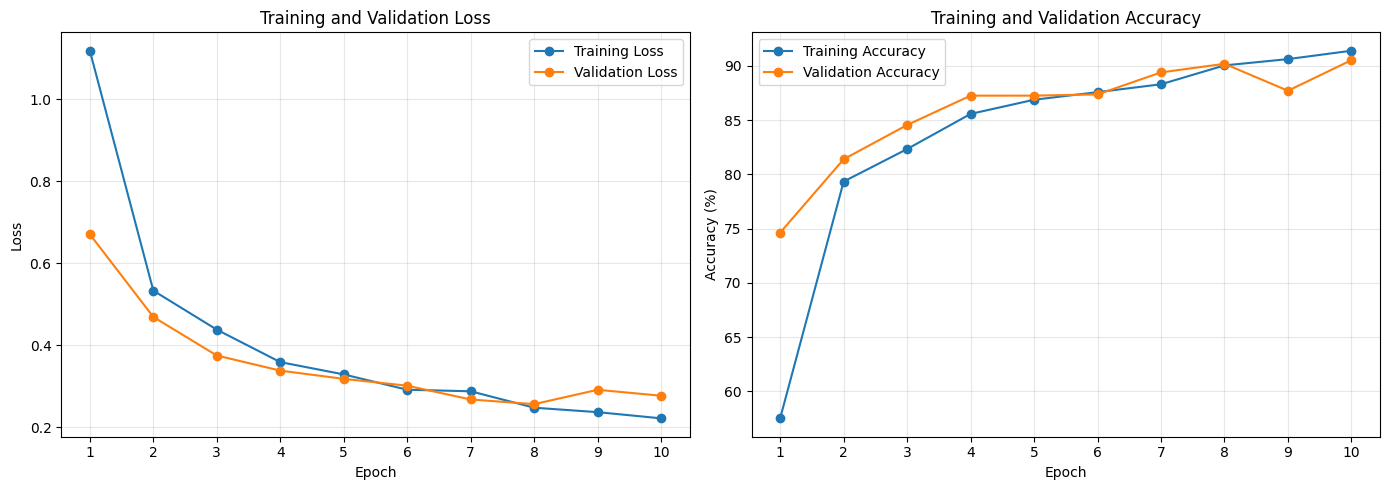

In [11]:
# Step 11: Plot training and validation loss/accuracy

epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker='o', label='Training Loss')
plt.plot(epochs, val_losses, marker='o', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accuracies, marker='o', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
# Step 12: Evaluate the best saved model on the test dataset

best_checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(best_checkpoint['model_state_dict'])
model.eval()

test_loss_total, test_correct, test_total = 0.0, 0, 0
all_predictions, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        test_loss_total += loss.item()
        predictions = outputs.argmax(dim=1)
        test_total += labels.size(0)
        test_correct += (predictions == labels).sum().item()
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = test_loss_total / len(test_loader)
test_accuracy = 100.0 * test_correct / test_total
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.2f}%')
print(f"Best Validation Accuracy: {best_checkpoint['best_val_accuracy']:.2f}%")


Test Loss: 0.2556
Test Accuracy: 90.64%
Best Validation Accuracy: 90.53%


              precision    recall  f1-score   support

    airplane       0.98      0.93      0.95       109
         car       0.93      0.95      0.94       145
         cat       0.82      0.77      0.79       133
         dog       0.68      0.72      0.70       105
      flower       0.92      0.96      0.94       127
       fruit       0.99      1.00      0.99       150
   motorbike       0.99      0.97      0.98       118

    accuracy                           0.91       887
   macro avg       0.90      0.90      0.90       887
weighted avg       0.91      0.91      0.91       887



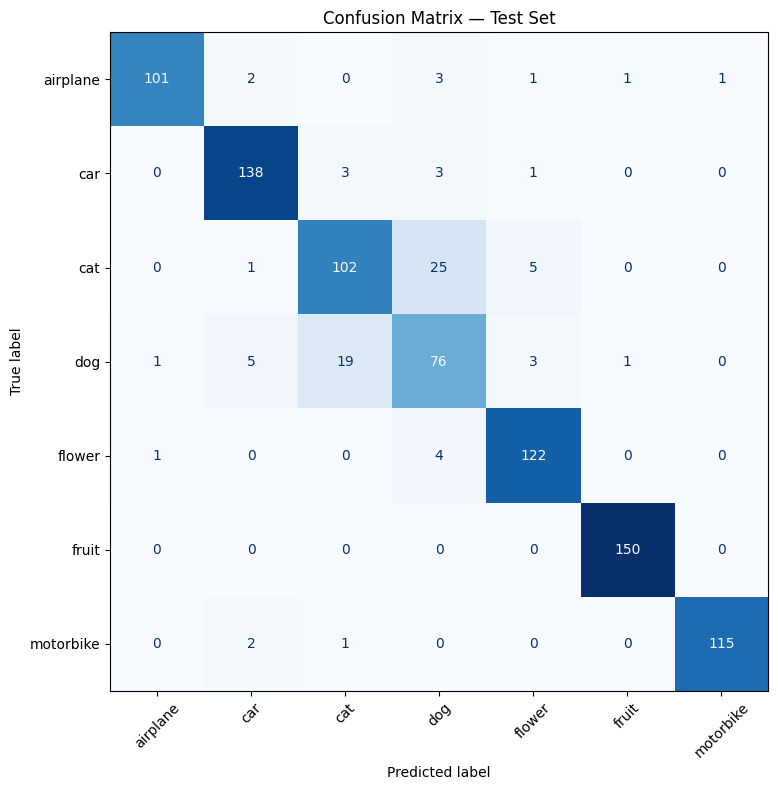

In [13]:
# Step 13: Confusion matrix and classification report

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print(classification_report(all_labels, all_predictions, target_names=selected_classes, zero_division=0))
cm = confusion_matrix(all_labels, all_predictions)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=selected_classes)
fig, ax = plt.subplots(figsize=(9, 8))
display.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.show()


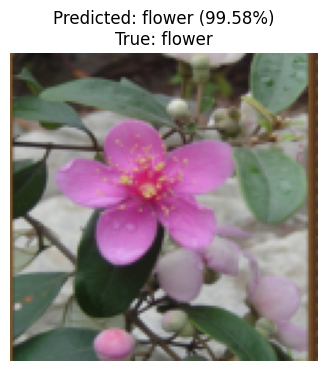

In [14]:
# Step 14: Predict one test image using the trained best model

model.eval()
image_tensor, true_label = test_dataset[0]
with torch.no_grad():
    logits = model(image_tensor.unsqueeze(0).to(device))
    probabilities = torch.softmax(logits, dim=1)
    confidence, predicted_index = probabilities.max(dim=1)

predicted_class = selected_classes[predicted_index.item()]
true_class = selected_classes[true_label]

# Undo normalization for display
image_to_show = image_tensor.permute(1, 2, 0).cpu().numpy()
image_to_show = (image_to_show * 0.5) + 0.5
image_to_show = np.clip(image_to_show, 0, 1)

plt.figure(figsize=(4, 4))
plt.imshow(image_to_show)
plt.title(f'Predicted: {predicted_class} ({confidence.item()*100:.2f}%)\nTrue: {true_class}')
plt.axis('off')
plt.show()


In [15]:
# Step 15: Confirm saved model/checkpoint files

print('Best model exists:', os.path.exists(best_model_path))
print('Best model size (MB):', round(os.path.getsize(best_model_path) / (1024 * 1024), 2))
print('Latest checkpoint exists:', os.path.exists(last_checkpoint_path))
print('Files in /kaggle/working:')
for item in os.listdir('/kaggle/working'):
    print('-', item)

print('IMPORTANT: After the notebook finishes, use Save Version (with output saved) in Kaggle to preserve /kaggle/working files as notebook outputs.')


Best model exists: True
Best model size (MB): 2.37
Latest checkpoint exists: True
Files in /kaggle/working:
- cnn_checkpoints
- best_model.pth
- __notebook__.ipynb
IMPORTANT: After the notebook finishes, use Save Version (with output saved) in Kaggle to preserve /kaggle/working files as notebook outputs.
